## Negative-binomial variational autoencoder (VAE) for single-cell transcriptomes of human pancreatic islets.

This analyis uses the Segerstolpe et al. 2016 (E-MTAB-5061), Smart-seq2, healthy and type 2 diabetes donors data.

In [1]:
import json
from pathlib import Path

import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np 
import scanpy as sc 
import torch  
from sklearn.cluster import KMeans 
from sklearn.decomposition import PCA 
from sklearn.metrics import ( 
    accuracy_score,
    adjusted_rand_score,
    f1_score,
    normalized_mutual_info_score,
)
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.preprocessing import StandardScaler  
from torch import nn  

In [111]:
DATA_PATH = "segerstolpe.h5ad"

CELL_TYPE_KEY = "cell type"
DONOR_KEY = "individual"

MIN_CELLS_PER_TYPE = 50
N_HVG = 2000

### Helper functions

In [48]:
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)

In [112]:
### Load data

adata = sc.read_h5ad(DATA_PATH)

In [113]:
adata

AnnData object with n_obs × n_vars = 3514 × 25444
    obs: 'cell type', 'individual', 'disease', 'quality'
    layers: None (.X)

In [114]:
adata.obs.head()

,cell type,individual,disease,quality
HP1502401_N13,not applicable,H2,normal,low quality cell
HP1502401_D14,not applicable,H2,normal,low quality cell
HP1502401_F14,not applicable,H2,normal,low quality cell
HP1502401_J13,not applicable,H2,normal,low quality cell
HP1502401_B13,not applicable,H2,normal,low quality cell


### Filtering cell and Quality control

The original paper has a a variable for quality data, the variable is being used to filter the data

In [116]:
adata.obs[CELL_TYPE_KEY] = adata.obs[CELL_TYPE_KEY].astype(str)
adata.obs[DONOR_KEY] = adata.obs[DONOR_KEY].astype(str)

adata = adata[adata.obs["quality"] == "OK"].copy()

# Remove cells without an assigned cell type
unannotated = {
    "nan",
    "NA",
    "None",
    "",
    "not applicable",
}

adata = adata[
    ~adata.obs[CELL_TYPE_KEY].isin(unannotated)
].copy()

adata.obs.head()

,cell type,individual,disease,quality
HP1502401_H13,gamma cell,H2,normal,OK
HP1502401_J14,alpha cell,H2,normal,OK
HP1502401_B14,beta cell,H2,normal,OK
HP1502401_A14,acinar cell,H2,normal,OK
HP1502401_C14,alpha cell,H2,normal,OK


In [117]:
adata.obs[CELL_TYPE_KEY].value_counts()

cell type
alpha cell                     886
ductal cell                    386
beta cell                      270
gamma cell                     197
acinar cell                    185
delta cell                     114
PSC cell                        54
unclassified endocrine cell     41
co-expression cell              39
endothelial cell                16
epsilon cell                     7
mast cell                        7
MHC class II cell                5
unclassified cell                2
Name: count, dtype: int64

In [119]:
counts = to_dense(adata.X)

if not np.allclose(counts, np.round(counts)):
    raise ValueError(
        "adata.X must contain raw integer counts "
        "(not RPKM or log values)."
    )

In [120]:
adata

AnnData object with n_obs × n_vars = 2209 × 25444
    obs: 'cell type', 'individual', 'disease', 'quality'
    layers: None (.X)

### Select highly variable genes(HVG)

HVG uses the log-normalised scale while the VAE uses the raw counts

In [121]:
normalised = adata.copy()

## normalised the raw count
sc.pp.normalize_total(normalised, target_sum=1e4)
sc.pp.log1p(normalised)

## Get the highly variable genes
sc.pp.highly_variable_genes(normalised, n_top_genes=N_HVG)
hvg = normalised.var["highly_variable"].values

## select the highly variable genes
adata_counts = adata[:, hvg].copy()
adata_norm = normalised[:, hvg].copy()

print("Raw counts:", adata_counts)
print("Normalized:", adata_norm)

Raw counts: AnnData object with n_obs × n_vars = 2209 × 2000
    obs: 'cell type', 'individual', 'disease', 'quality'
    layers: None (.X)
Normalized: AnnData object with n_obs × n_vars = 2209 × 2000
    obs: 'cell type', 'individual', 'disease', 'quality'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: None (.X)


In [122]:
## Model Config.

N_HIDDEN = 128
N_LATENT = 10
LEARNING_RATE = 1e-3
EPOCHS = 150
BATCH_SIZE = 128
SEED = 42
N_HOLDOUT_DONORS = 2
N_LATENT = 10

## Set seed

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")

Using device: cpu


In [123]:
counts = to_dense(adata_counts.X)
labels = adata_counts.obs["cell type"].values

In [124]:
CELL_TYPE_KEY = "cell type"
DONOR_KEY = "individual"
DISEASE_KEY = "disease"

labels = adata_counts.obs[CELL_TYPE_KEY].values

obs_keys = [
    CELL_TYPE_KEY,
    DONOR_KEY
]

if DISEASE_KEY in adata_counts.obs:
    adata_counts.obs[DISEASE_KEY] = (
        adata_counts.obs[DISEASE_KEY].astype(str)
    )
    obs_keys.append(DISEASE_KEY)

In [125]:
rng = np.random.default_rng(SEED)

donors = np.array(
    sorted(adata_counts.obs[DONOR_KEY].unique())
)

holdout = rng.choice(
    donors,
    size=N_HOLDOUT_DONORS,
    replace=False
)

is_test = adata_counts.obs[
    DONOR_KEY
].isin(holdout).values

In [148]:
donors

array(['H1', 'H2', 'H3', 'H4', 'H5', 'H6', 'T2D1', 'T2D2', 'T2D3', 'T2D4'],
      dtype='<U4')

In [127]:
print(
    f"{adata_counts.n_obs} cells, "
    f"{adata_counts.n_vars} genes, "
    f"{len(donors)} donors"
)

print(f"Held out donors: {list(holdout)}")

2209 cells, 2000 genes, 10 donors
Held out donors: [np.str_('H1'), np.str_('T2D2')]


## Principal component analysis (PCA)
Baseline for the VAE. 

PCA on standardised log-normalised expression, fitted on training donors only

In [128]:
Xn = to_dense(adata_norm.X)
scaler = StandardScaler().fit(Xn[~is_test])
Xs = np.clip(scaler.transform(Xn), -10, 10)
Z_pca = PCA(n_components=N_LATENT, random_state=SEED).fit(Xs[~is_test]).transform(Xs)

In [129]:
Z_pca.shape

(2209, 10)

## The Negative binomial PyTorch neural-network model

In [131]:
## Helper Function

def negative_binomial_log_prob(x, mean, log_theta):
    """Log-likelihood of a negative binomial with mean `mean` and inverse dispersion theta."""
    eps = 1e-8
    theta = torch.exp(log_theta)
    log_theta_mu = torch.log(theta + mean + eps)
    return (
        torch.lgamma(x + theta)
        - torch.lgamma(theta)
        - torch.lgamma(x + 1.0)
        + theta * (torch.log(theta + eps) - log_theta_mu)
        + x * (torch.log(mean + eps) - log_theta_mu)
    )

In [132]:
class NBVAE(nn.Module):
    def __init__(self, n_genes, n_hidden=128, n_latent=10, dropout=0.1):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_genes, n_hidden), nn.LayerNorm(n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_hidden), nn.LayerNorm(n_hidden), nn.ReLU(), nn.Dropout(dropout),
        )
        self.mu = nn.Linear(n_hidden, n_latent)
        self.logvar = nn.Linear(n_hidden, n_latent)
        self.decoder = nn.Sequential(
            nn.Linear(n_latent, n_hidden), nn.LayerNorm(n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_hidden), nn.LayerNorm(n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_genes),
        )
        self.log_theta = nn.Parameter(torch.zeros(n_genes))  # gene-wise dispersion

    def encode(self, x):
        h = self.encoder(torch.log1p(x))
        return self.mu(h), self.logvar(h).clamp(-10.0, 10.0)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        rho = torch.softmax(self.decoder(z), dim=-1)  # gene proportions per cell
        library = x.sum(dim=-1, keepdim=True)  # observed library size as offset
        return library * rho, mu, logvar

In [133]:
def train_vae(counts, device, n_hidden=128,
    n_latent=10,
    lr=1e-3,
    epochs=100,
    batch_size=128,
):
    model = NBVAE(counts.shape[1], n_hidden, n_latent).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    data = torch.tensor(counts, dtype=torch.float32)
    n = data.shape[0]
    warmup = max(1, epochs // 3)  # KL annealing
    history = []
    for epoch in range(epochs):
        model.train()
        beta = min(1.0, (epoch + 1) / warmup)
        perm = torch.randperm(n)
        total = 0.0
        for i in range(0, n, batch_size):
            x = data[perm[i : i + batch_size]].to(device)
            mean, mu, logvar = model(x)
            rec = -negative_binomial_log_prob(x, mean, model.log_theta).sum(dim=-1).mean()
            kl = (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=-1)).mean()
            loss = rec + beta * kl
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            opt.step()
            total += loss.item() * x.shape[0]
        history.append(total / n)
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"epoch {epoch + 1:4d}/{epochs}  loss {history[-1]:.2f}  beta {beta:.2f}")
    return model, history

In [134]:
@torch.no_grad()
def embed(model, counts, device):
    model.eval()
    mu, _ = model.encode(torch.tensor(counts, dtype=torch.float32, device=device))
    return mu.cpu().numpy()

In [135]:
model, history = train_vae(
    counts[~is_test],
    device=device,
    n_hidden=128,
    n_latent=N_LATENT,
    lr=1e-3,
    epochs=150,
    batch_size=128
)

epoch    1/100  loss 6414.14  beta 0.03
epoch   10/100  loss 3496.64  beta 0.30
epoch   20/100  loss 3124.43  beta 0.61
epoch   30/100  loss 2973.47  beta 0.91
epoch   40/100  loss 2859.76  beta 1.00
epoch   50/100  loss 2778.17  beta 1.00
epoch   60/100  loss 2711.09  beta 1.00
epoch   70/100  loss 2656.08  beta 1.00
epoch   80/100  loss 2611.32  beta 1.00
epoch   90/100  loss 2571.79  beta 1.00
epoch  100/100  loss 2540.70  beta 1.00


In [ ]:
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("NB-VAE Training Loss")
plt.show()

In [136]:
Z_vae = embed(model, counts, device)

### Visualise model output

In [102]:
def plot_umap(Z, obs, keys, seed):
    emb = sc.AnnData(Z.astype(np.float32))
    emb.obs = obs[keys].astype("category").copy()
    emb.obs_names = obs.index

    sc.pp.neighbors(emb, use_rep="X", n_neighbors=15)
    sc.tl.umap(emb, random_state=seed)

    sc.pl.umap(
        emb,
        color=keys,
        show=True,
        wspace=0.5
    )

obs_keys = ["cell type","individual", "disease"]

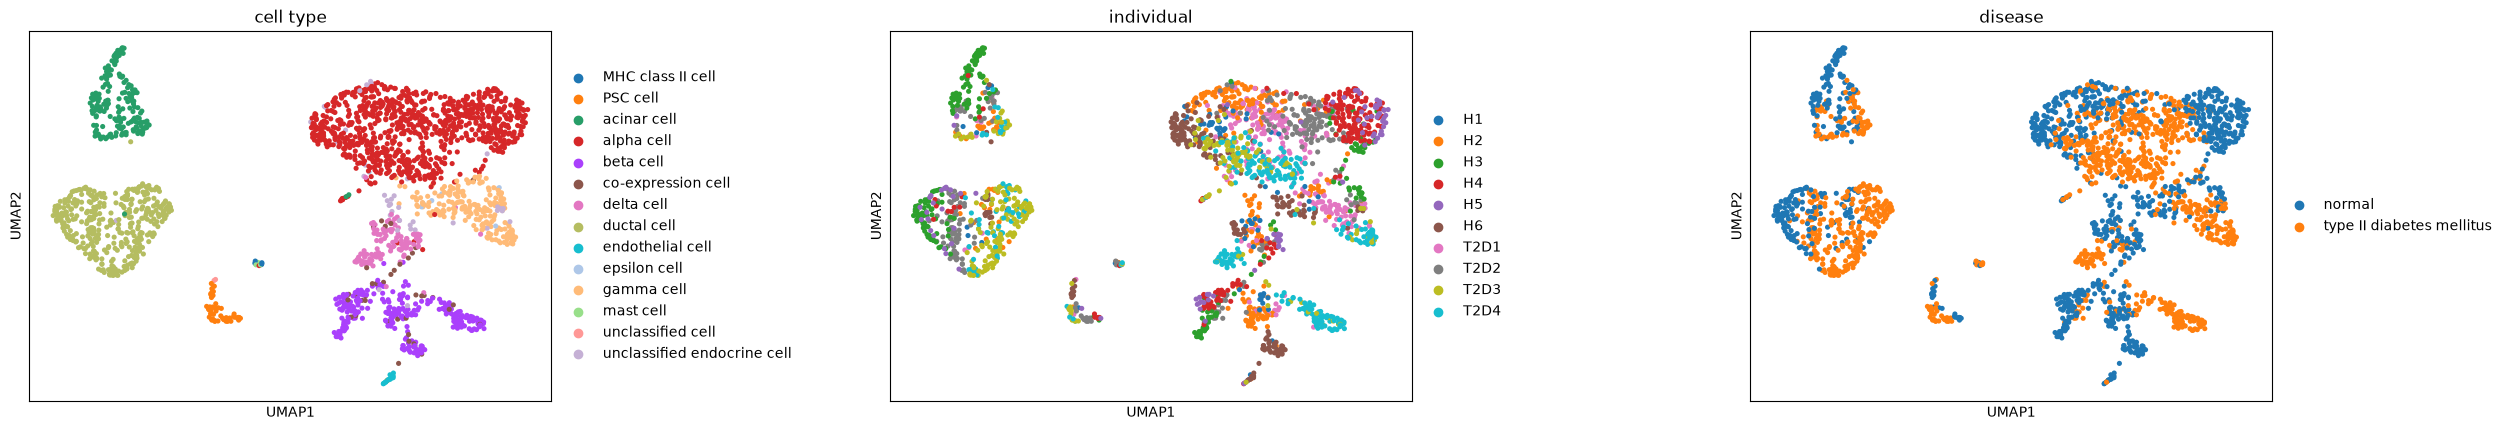

In [137]:
plot_umap(
    Z_pca,
    adata_norm.obs,
    obs_keys,
    SEED
)

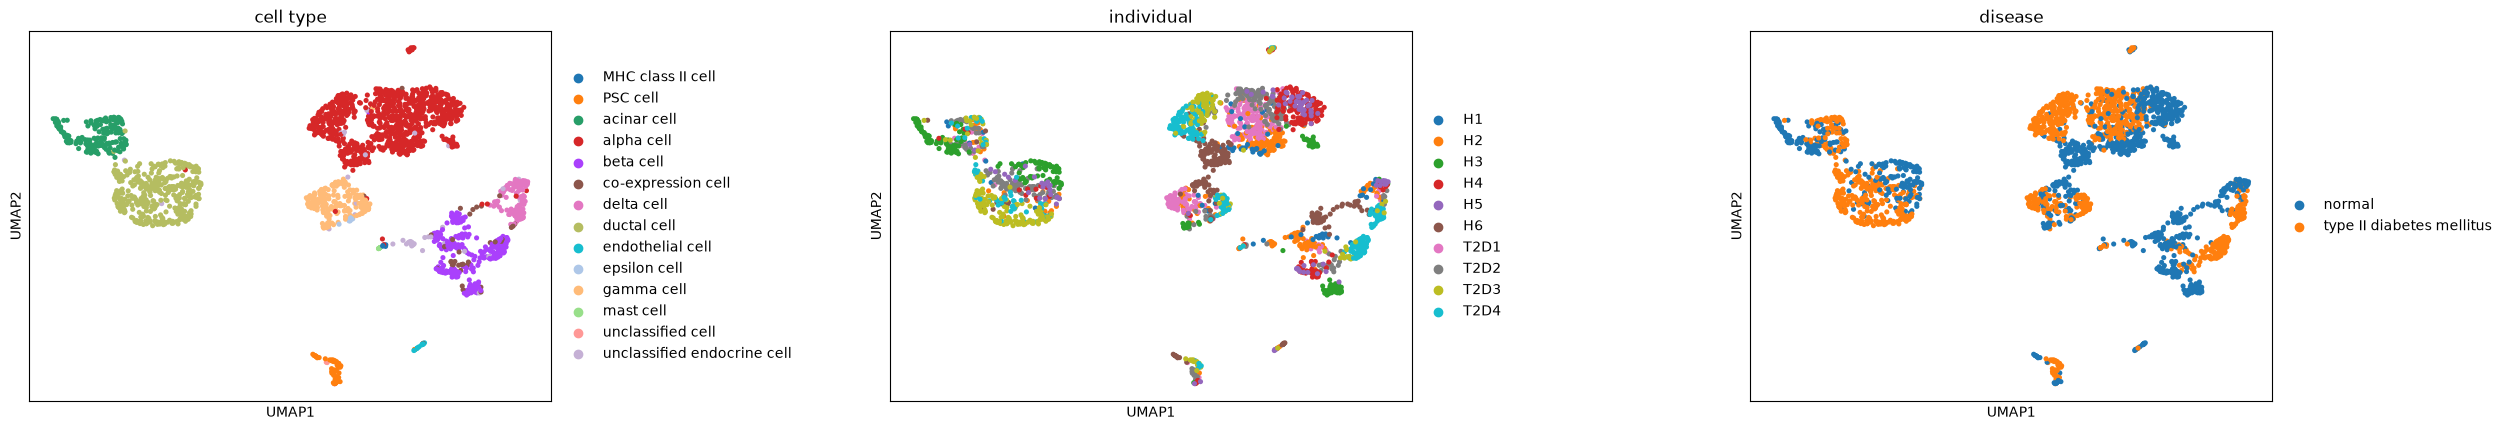

In [138]:
plot_umap(Z_vae, adata_counts.obs, obs_keys, SEED)

### Evaluation of the two methods

In [139]:
def evaluate(Z, labels, is_test, seed):
    knn = KNeighborsClassifier(n_neighbors=15).fit(Z[~is_test], labels[~is_test])
    pred = knn.predict(Z[is_test])
    clusters = KMeans(n_clusters=len(np.unique(labels)), n_init=10, random_state=seed).fit_predict(Z)
    return {
        "knn_accuracy_heldout_donors": float(accuracy_score(labels[is_test], pred)),
        "knn_macro_f1_heldout_donors": float(f1_score(labels[is_test], pred, average="macro")),
        "kmeans_ARI_all_cells": float(adjusted_rand_score(labels, clusters)),
        "kmeans_NMI_all_cells": float(normalized_mutual_info_score(labels, clusters)),
    }

In [140]:
pca_evals = evaluate(
    Z_pca,
    labels,
    is_test,
    SEED,
)

pca_evals

{'knn_accuracy_heldout_donors': 0.9312320916905444,
 'knn_macro_f1_heldout_donors': 0.683569397686798,
 'kmeans_ARI_all_cells': 0.7916951739994808,
 'kmeans_NMI_all_cells': 0.7643362406036583}

In [141]:
vae_evals = evaluate(
    Z_vae,
    labels,
    is_test,
    SEED,
)

vae_evals

{'knn_accuracy_heldout_donors': 0.9398280802292264,
 'knn_macro_f1_heldout_donors': 0.7405332947370059,
 'kmeans_ARI_all_cells': 0.38841440656532017,
 'kmeans_NMI_all_cells': 0.7049912387081273}

## Findings

Both PCA and the Negative-binomial VAE learned representations that generalized to unseen donors, but they showed different strengths.

- Held-out donor classification: The NB-VAE performed slightly better, achieving 93.98% accuracy and 0.741 macro F1, compared with 93.12% accuracy and 0.684 macro F1 for PCA.
  
- Cell-type clustering: PCA performed substantially better, with 0.792 ARI and 0.764 NMI, compared with 0.388 ARI and 0.705 NMI for the NB-VAE.
  
- Overall: The NB-VAE provided better supervised cell-type classification on unseen donors, while PCA produced substantially better-separated cell-type clusters.

These results suggest that nonlinear representation learning with the NB-VAE improves classification performance but does not necessarily produce more naturally clusterable representations than PCA for this dataset.